# Human activity recognition from smartphone sensors: why the validation split matters
**Data.** UCI HAR (Anguita et al., 2013): 30 volunteers wore a smartphone on the waist while walking, walking upstairs or downstairs, sitting, standing and lying. Each 2.56-second window of accelerometer and gyroscope signal is summarised by 561 engineered features. There are 10,299 windows, already split by **person**: 21 people for training and 9 for testing.

**Questions.** How accurately can activity be recognised for a *new* person? Which activities get confused? How badly does a careless random split overstate performance, the same leakage problem that affects any model scored on customers, patients or firms seen in training?

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score, KFold, GroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
h = pd.read_csv("data/uci_har.csv.gz")
feats = [c for c in h.columns if c not in ("subject", "Activity", "split")]
tr, te = h[h.split == "train"], h[h.split == "test"]
print(f"{len(h):,} windows x {len(feats)} features; {tr.subject.nunique()} training people, {te.subject.nunique()} test people; overlap {len(set(tr.subject) & set(te.subject))}")
h.Activity.value_counts()

10,299 windows x 561 features; 21 training people, 9 test people; overlap 0


Activity
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64

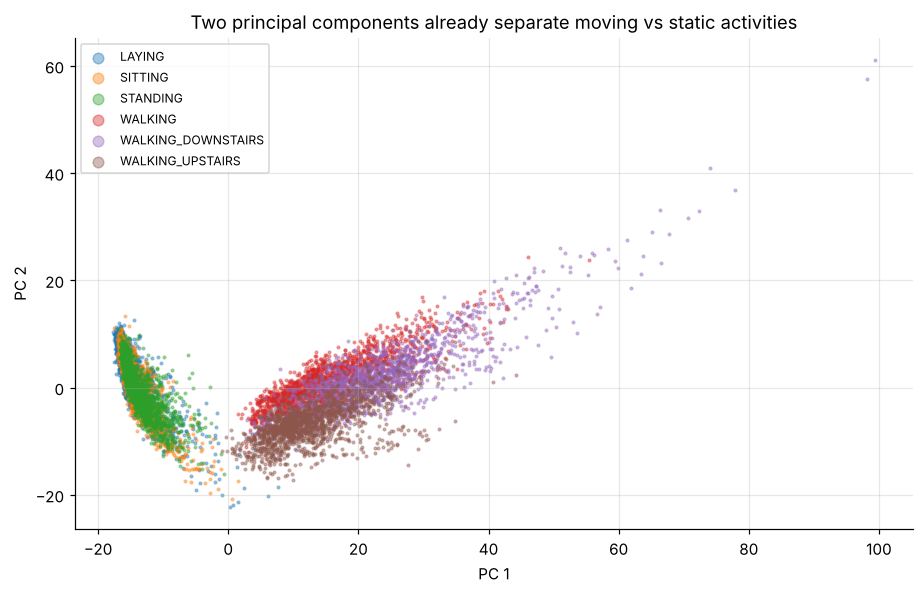

In [2]:
Z = PCA(2).fit_transform(StandardScaler().fit_transform(h[feats]))
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for a, g in h.assign(pc1=Z[:, 0], pc2=Z[:, 1]).groupby("Activity"):
    ax.scatter(g.pc1, g.pc2, s=3, alpha=.4, label=a)
ax.legend(markerscale=4, fontsize=8); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
ax.set_title("Two principal components already separate moving vs static activities")
plt.tight_layout(); plt.savefig(IMG / "pca.png", bbox_inches="tight"); plt.show()

## Leakage check: random folds vs person-grouped folds
The same model is cross-validated on the training people two ways: with random 5-fold splits, where windows from the same person land in both training and validation folds, and with **GroupKFold by person**, where each validation fold contains only unseen people.

In [3]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000))
acc_random = cross_val_score(model, tr[feats], tr.Activity, cv=KFold(5, shuffle=True, random_state=0)).mean()
acc_group = cross_val_score(model, tr[feats], tr.Activity, cv=GroupKFold(5), groups=tr.subject).mean()
print(f"random-split CV accuracy {acc_random:.3f}  vs  person-grouped CV accuracy {acc_group:.3f}  (gap {100 * (acc_random - acc_group):.1f} points)")

random-split CV accuracy 0.983  vs  person-grouped CV accuracy 0.934  (gap 4.9 points)


In [4]:
models = {"logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000)),
          "linear SVM": make_pipeline(StandardScaler(), LinearSVC(C=0.05, max_iter=20000)),
          "gradient boosting": HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=0)}
res, preds = {}, {}
for n, m in models.items():
    m.fit(tr[feats], tr.Activity); p = m.predict(te[feats]); preds[n] = p
    res[n] = {"test accuracy (9 new people)": accuracy_score(te.Activity, p), "macro F1": f1_score(te.Activity, p, average="macro")}
pd.DataFrame(res).T.round(3)

,test accuracy (9 new people),macro F1
logistic regression,0.951,0.952
linear SVM,0.960,0.961
gradient boosting,0.937,0.936


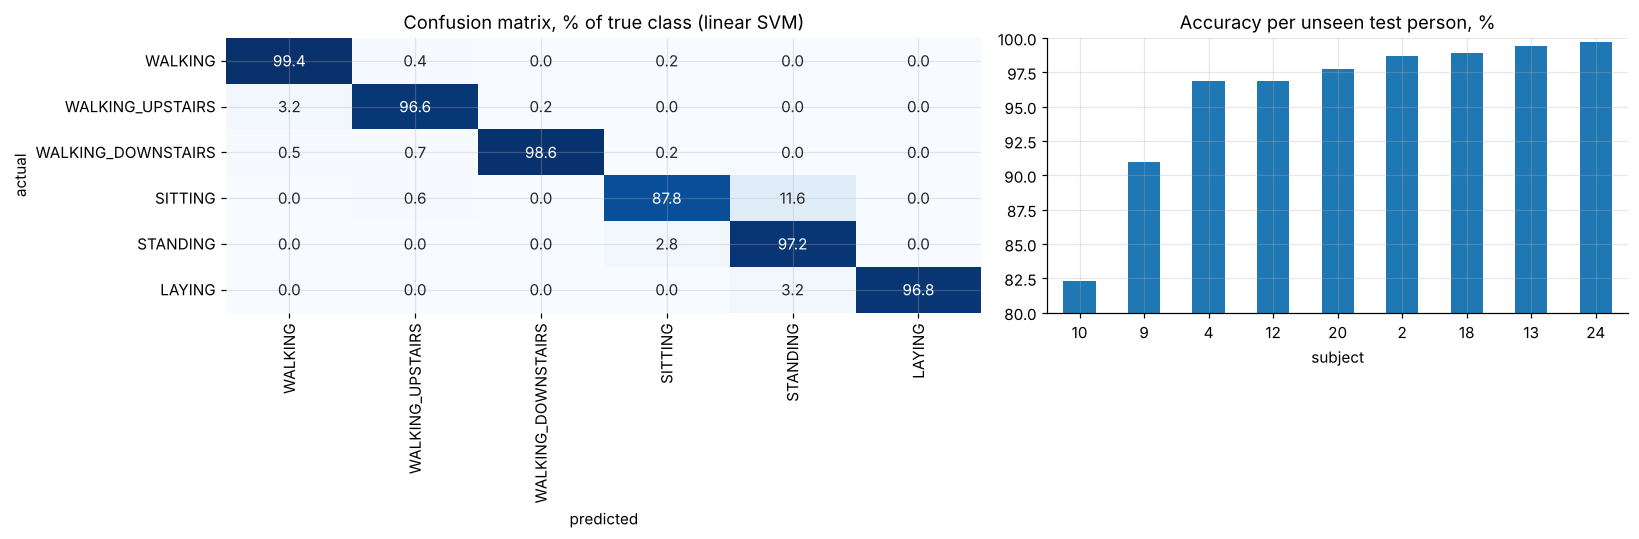

per-person accuracy ranges from 82.3% to 99.7%


In [5]:
best = max(res, key=lambda k: res[k]["test accuracy (9 new people)"])
labels = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
cm = confusion_matrix(te.Activity, preds[best], labels=labels)
cmn = pd.DataFrame(100 * cm / cm.sum(axis=1, keepdims=True), index=labels, columns=labels)
per_person = te.assign(ok=preds[best] == te.Activity).groupby("subject").ok.mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(cmn, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar=False); axes[0].set_title(f"Confusion matrix, % of true class ({best})")
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("actual")
per_person.sort_values().plot.bar(ax=axes[1], color="C0", rot=0, title="Accuracy per unseen test person, %"); axes[1].set_ylim(80, 100)
plt.tight_layout(); plt.savefig(IMG / "confusion_per_person.png", bbox_inches="tight"); plt.show()
print(f"per-person accuracy ranges from {per_person.min():.1f}% to {per_person.max():.1f}%")

In [6]:
# which sensor groups carry the signal? retrain on feature subsets
groups = {"time-domain body acceleration": [f for f in feats if f.startswith("tBodyAcc")], "time-domain gravity": [f for f in feats if f.startswith("tGravityAcc")],
          "gyroscope (time + freq)": [f for f in feats if "Gyro" in f], "frequency-domain acceleration": [f for f in feats if f.startswith("fBodyAcc")],
          "angle features": [f for f in feats if f.startswith("angle")]}
sub = {}
for g, cols in groups.items():
    m = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000)).fit(tr[cols], tr.Activity)
    sub[g] = {"features": len(cols), "test accuracy alone": accuracy_score(te.Activity, m.predict(te[cols]))}
pd.DataFrame(sub).T.sort_values("test accuracy alone", ascending=False).round(3)

,features,test accuracy alone
time-domain gravity,53.0,0.867
time-domain body acceleration,106.0,0.842
gyroscope (time + freq),213.0,0.818
frequency-domain acceleration,171.0,0.791
angle features,7.0,0.505


## Findings
* **New people can be recognised accurately:** a linear SVM reaches **96.0% accuracy** (macro F1 0.96) on 9 people never seen in training, ahead of logistic regression (95.1%) and gradient boosting (93.7%). With 561 well-engineered features, a regularised linear model is enough.
* **A random split overstates accuracy.** Random 5-fold cross-validation reports 98.3%, while person-grouped folds give 93.4%, a 4.9-point illusion. Windows from the same person are near-duplicates, so a random split lets the model "recognise the person" rather than the activity. The same leakage affects models of customers, patients or firms.
* **The hard case is sitting vs standing:** 11.6% of sitting windows are read as standing. Both are static with the phone at the waist, so posture shows only through the small gravity tilt. Walking types are recognised at 97-99%.
* **People differ:** accuracy ranges from 82% (subject 10) to 99.7% per unseen person. In production, a short per-user calibration would help most for the few people unlike the training group.
* **Where the signal lives:** gravity-direction features alone reach 86.7% and body-acceleration features 84.2%. Gyroscope and frequency-domain features add the remaining precision; the 7 angle features alone manage only 50.5%.